In [44]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from pathlib import Path

DATA_DIR = Path("dataset")
for data_file in sorted(DATA_DIR.glob("*.csv")):
    print(data_file)

dataset/sample_submission.csv
dataset/test.csv
dataset/train.csv


In [45]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

### リポジトリ内のデータを読み込む設定

リポジトリ直下の `dataset/` にある `train.csv`、`test.csv`、`sample_submission.csv` を読み込みます。

In [46]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1454 entries, 0 to 1453
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 1454 non-null   int64  
 1   Lat_Dec            1454 non-null   float64
 2   Lon_Dec            1454 non-null   float64
 3   NO2uM              1454 non-null   float64
 4   NO3uM              1454 non-null   float64
 5   NH3uM              1454 non-null   float64
 6   R_TEMP             1454 non-null   float64
 7   R_Depth            1454 non-null   int64  
 8   R_Sal              1454 non-null   float64
 9   R_DYNHT            1454 non-null   float64
 10  R_Nuts             1454 non-null   float64
 11  R_Oxy_micromol.Kg  1454 non-null   float64
 12  Unnamed: 12        0 non-null      float64
 13  PO4uM              1454 non-null   float64
 14  SiO3uM             1454 non-null   float64
 15  TA1.x              1454 non-null   float64
 16  Salinity1          1454 non-null   

In [47]:
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load data
# train = pd.read_csv("/kaggle/input/eds-232-ocean-chemistry-prediction-for-calcofi/train.csv")
# test = pd.read_csv("/kaggle/input/eds-232-ocean-chemistry-prediction-for-calcofi/test.csv")

# Drop unneeded columns and handle missing values
train = train.drop(columns=["Unnamed: 12", "id"])  # Dropping unnecessary columns

# Find common columns between train and test (excluding "DIC" from train)
common_columns = train.drop(columns=["DIC"]).columns.intersection(test.columns)

# Select the common columns for both train and test
X = train[common_columns]
y = train["DIC"]
test = test[common_columns]

# Split before fitting preprocessing to avoid validation-data leakage
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit imputation and standardization statistics on training rows only
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
test = imputer.transform(test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
test_scaled = scaler.transform(test)


In [48]:
from torch.utils.data import Dataset, DataLoader

class OceanChemistryDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = OceanChemistryDataset(X_train, y_train)
val_dataset = OceanChemistryDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)


In [49]:
class MLPModel(nn.Module):
    def __init__(self, input_size):
        super(MLPModel, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(64, 1)  # Output layer for regression

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.fc3(x)
        return x

# Initialize the model
model = MLPModel(input_size=X_train.shape[1])
print(X_train.shape)


(1163, 15)


In [50]:
import torch.optim as optim
from sklearn.metrics import r2_score

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def evaluate_loader(model, loader):
    predictions = []
    targets = []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            predictions.append(model(X_batch).squeeze(-1))
            targets.append(y_batch)
    predictions = torch.cat(predictions)
    targets = torch.cat(targets)
    loss = criterion(predictions, targets).item()
    r2 = r2_score(targets.cpu().numpy(), predictions.cpu().numpy())
    return loss, r2

# Training function
def train_model(model, train_loader, val_loader, epochs=5000):
    history = {"train_loss": [], "val_loss": [], "train_r2": [], "val_r2": []}
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        samples_seen = 0
        train_predictions = []
        train_targets = []
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch).squeeze(-1)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(y_batch)
            samples_seen += len(y_batch)
            train_predictions.append(outputs.detach())
            train_targets.append(y_batch.detach())

        # Use the predictions made in train mode during this epoch.
        train_loss = running_loss / samples_seen
        train_r2 = r2_score(
            torch.cat(train_targets).cpu().numpy(),
            torch.cat(train_predictions).cpu().numpy(),
        )

        # Validate with the weights after this epoch's training.
        model.eval()
        val_loss, val_r2 = evaluate_loader(model, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_r2"].append(train_r2)
        history["val_r2"].append(val_r2)

        if epoch % 100 == 0:
            print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Validation Loss: {val_loss:.4f}, Train R²: {train_r2:.4f}, Validation R²: {val_r2:.4f}")
    return history

# Train the model
history = train_model(model, train_loader, val_loader, epochs=5000)


Epoch 1/5000, Train Loss: 4641121.0851, Validation Loss: 4608102.5000, Train R²: -366.0457, Validation R²: -343.7223
Epoch 101/5000, Train Loss: 14879.8218, Validation Loss: 15344.9932, Train R²: -0.1768, Validation R²: -0.1479
Epoch 201/5000, Train Loss: 2403.4414, Validation Loss: 3134.6951, Train R²: 0.8099, Validation R²: 0.7655
Epoch 301/5000, Train Loss: 796.4325, Validation Loss: 1005.5947, Train R²: 0.9370, Validation R²: 0.9248
Epoch 401/5000, Train Loss: 470.3794, Validation Loss: 602.9266, Train R²: 0.9628, Validation R²: 0.9549
Epoch 501/5000, Train Loss: 271.8647, Validation Loss: 339.3726, Train R²: 0.9785, Validation R²: 0.9746
Epoch 601/5000, Train Loss: 183.3983, Validation Loss: 198.7885, Train R²: 0.9855, Validation R²: 0.9851
Epoch 701/5000, Train Loss: 120.7769, Validation Loss: 143.7549, Train R²: 0.9904, Validation R²: 0.9892
Epoch 801/5000, Train Loss: 106.0692, Validation Loss: 116.1066, Train R²: 0.9916, Validation R²: 0.9913
Epoch 901/5000, Train Loss: 65.644

In [51]:
# Convert the test set into a torch tensor
test_tensor = torch.tensor(test_scaled, dtype=torch.float32)

# Set the model to evaluation mode
model.eval()

# Make predictions
with torch.no_grad():
    predictions = model(test_tensor).squeeze().numpy()

# Prepare submission
submission = pd.DataFrame({"id": range(1455, 1455 + len(predictions)), "DIC": predictions})
submission.to_csv("submission.csv", index=False)


### 学習曲線

各エポックで、訓練損失と訓練 R² は `model.train()` 中のバッチ予測から計算します。訓練損失は `running_loss` を処理したサンプル数で割った平均です。そのエポックの学習後、`model.eval()` と `torch.no_grad()` で検証損失と検証 R² を計算し、同じエポックの履歴に記録します。

学習・検証が完了してから、左にこの訓練集合・検証集合の MSE、右にそれぞれの R² を表示します。凡例の `Train` は訓練集合、`Validation` は検証集合を指します。
正解の `DIC` を含む `train.csv`（1,454件）を、訓練集合80%（1,163件）と検証集合20%（291件）に分割しています。

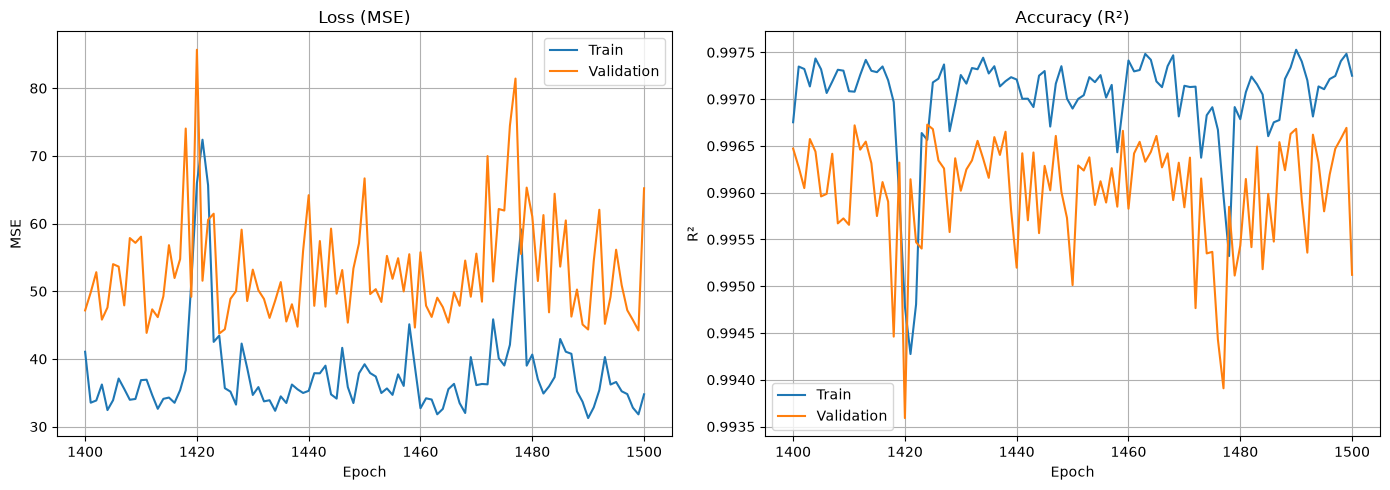

In [52]:
import matplotlib.pyplot as plt

plot_start_epoch = 1400
plot_end_epoch = 1500
last_epoch = min(plot_end_epoch, len(history["train_loss"]))
if not 1 <= plot_start_epoch <= last_epoch:
    raise ValueError("表示範囲は 1 <= 開始エポック <= 終了エポック（履歴の範囲内）にしてください。")
epoch_slice = slice(plot_start_epoch - 1, last_epoch)
epochs = range(plot_start_epoch, last_epoch + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["train_loss"][epoch_slice], label="Train")
axes[0].plot(epochs, history["val_loss"][epoch_slice], label="Validation")
axes[0].set_title("Loss (MSE)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_r2"][epoch_slice], label="Train")
axes[1].plot(epochs, history["val_r2"][epoch_slice], label="Validation")
axes[1].set_title("Accuracy (R²)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("R²")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [53]:
# score: 6.08783
# name: 杉浦孔明
# id: 123456

- 標準化に用いる平均値と標準偏差は、全体のそれではなく訓練データのものだけにする
- 5000エポックではなく、Early Stopping
- バッチサイズの比較（16, 32, 64, 128, 256）
- 学習率を下げるアルゴリズムの検証
    - 初期学習率の比較（1e-4, 3e-4, 1e-3, 3e-3）
    - ReduceLROnPlateau（検証損失が改善しなくなったタイミングで学習率を下げる）
    - コサインアニーリング（学習率を滑らかに下げる）
- 最適化手法（重み更新）の比較
    - AdamW
- 損失関数の比較
- 活性化関数の比較